# PredictiBall: Predicting International Football Results

**Author:** Ali Abu Salah · Data Science & AI Engineer  
**Tools:** Python · pandas · scikit-learn · matplotlib  
**Data:** international men's football results, 1872 – Oct 2026 (`results.csv`, 49,945 matches)

---

## Question

> **How well can we predict the result of an international match (home win / draw / away win) before it is played, and which ingredients actually help?**

This notebook builds the answer step by step, with honest testing at every stage:

1. Clean and explore the data
2. Build **leak-free** features: Elo ratings, recent form, rest days
3. Compare **baselines and several models** (logistic regression, random forest, gradient boosting, Poisson goals model, ensemble)
4. Evaluate on matches the models never saw: **2023 → Oct 2026, including the 2026 World Cup**
5. Read the results carefully: what is real, what is noise

> **Limits.** The data holds **results only**: no lineups, injuries, xG or odds. Football is noisy, so expect modest accuracy. This is a modelling exercise, not betting advice.

## Contents

| # | Section |
|---|---------|
| 1 | Setup |
| 2 | Load & clean |
| 3 | Exploratory analysis |
| 4 | Metrics and baselines |
| 5 | Elo ratings |
| 6 | Form features (leak-free) |
| 7 | Train / validation / test split |
| 8 | Models and tuning |
| 9 | Test results |
| 10 | Is the improvement real? |
| 11 | Calibration and errors |
| 12 | What drives the predictions? |
| 13 | World Cup 2026 backtest |
| 14 | Predict any match |
| 15 | Who rose and who fell: Elo around the 2026 World Cup |
| 16 | Findings, limits, next steps |

## 1. Setup

Install once if needed: `pip install pandas numpy scipy scikit-learn matplotlib`.  
Put `results.csv` next to this notebook, or change `DATA_PATH` below.

In [1]:
import difflib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import poisson

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

# ---------- configuration ----------
DATA_PATH   = Path("results.csv")   # change this if your file lives elsewhere
SAVE_FIGS   = False                 # True -> every chart is also saved to ./figures
SEED        = 42
TRAIN_START = "1990-01-01"          # first match used to FIT models (Elo still learns from 1872)
VALID_START = "2019-01-01"          # validation period: used to tune settings
TEST_START  = "2023-01-01"          # test period: looked at once, after all choices are made
CLASSES     = ["H", "D", "A"]       # home win, draw, away win (ordered, needed for RPS)
LABELS      = {"H": "Home win", "D": "Draw", "A": "Away win"}

# ---------- visual style ----------
INK, MUTED, GRID, BG = "#2b2118", "#8a7a60", "#e6d8ba", "#faf6ee"
TEAL, TERRA, PURPLE, AMBER = "#0f8fb0", "#b4532a", "#7c5cf0", "#c27c0e"   # fixed order, colour-blind checked
OUTCOME_COLORS = {"H": TEAL, "D": MUTED, "A": TERRA}

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5, "figure.dpi": 110, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.4f}".format

def show(fig, name):
    """Display a figure and optionally save it."""
    if SAVE_FIGS:
        Path("figures").mkdir(exist_ok=True)
        fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 2. Load & clean

Checks: structure, missing values, duplicates, score sanity, chronological order. Matches get a stable `match_id` after sorting by date. The match **outcome** is derived from the final score (extra time included, penalty shoot-outs excluded, so a shoot-out decider counts as a draw).

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Rows: {len(raw):,}  |  Columns: {raw.shape[1]}")
print(f"Dates: {raw['date'].min():%d %b %Y} to {raw['date'].max():%d %b %Y}")
print(f"Missing values: {int(raw.isna().sum().sum())}  |  Fully duplicated rows: {int(raw.duplicated().sum())}")
print(f"Negative scores: {int((raw[['home_score', 'away_score']] < 0).sum().sum())}")
print(f"Teams: {pd.concat([raw['home_team'], raw['away_team']]).nunique()}  |  Tournaments: {raw['tournament'].nunique()}")
raw.head()

Rows: 49,945  |  Columns: 9
Dates: 30 Nov 1872 to 06 Oct 2026
Missing values: 0  |  Fully duplicated rows: 0
Negative scores: 0
Teams: 337  |  Tournaments: 225


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


In [3]:
df = raw.sort_values("date", kind="stable").reset_index(drop=True)
df["match_id"] = df.index
df["neutral"] = df["neutral"].astype(bool)
df["result"] = np.select([df["home_score"] > df["away_score"], df["home_score"] < df["away_score"]], ["H", "A"], "D")

# A team can play twice on the same day (rare). This matters later: features must not mix those matches up.
long_days = pd.concat([df[["date", "home_team"]].rename(columns={"home_team": "team"}),
                       df[["date", "away_team"]].rename(columns={"away_team": "team"})])
same_day = long_days.duplicated(["date", "team"], keep=False).sum()
print(f"Team-matches that share a date with another match of the same team: {same_day}")
print(f"Already in chronological order: {raw['date'].is_monotonic_increasing}")

Team-matches that share a date with another match of the same team: 299
Already in chronological order: True


## 3. Exploratory analysis

Four quick looks that shape the modelling: how the data grew, how outcomes are split, how big home advantage is, and how scoring changed.

Overall outcome split:  Home win 49.0%  |  Draw 22.7%  |  Away win 28.3%
Average goals per match: 2.94
Played at a neutral venue: 26.6%   |   Friendlies: 36.6%


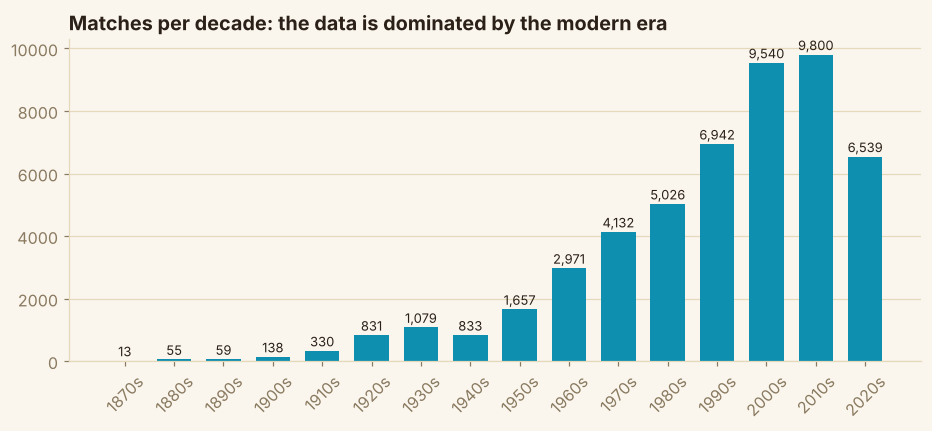

In [4]:
df["year"] = df["date"].dt.year
df["decade"] = df["year"] // 10 * 10

overall = df["result"].value_counts(normalize=True).reindex(CLASSES) * 100
print("Overall outcome split:  " + "  |  ".join(f"{LABELS[c]} {overall[c]:.1f}%" for c in CLASSES))
print(f"Average goals per match: {(df['home_score'] + df['away_score']).mean():.2f}")
print(f"Played at a neutral venue: {df['neutral'].mean() * 100:.1f}%   |   Friendlies: {(df['tournament'] == 'Friendly').mean() * 100:.1f}%")

per_decade = df.groupby("decade").size()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(per_decade.index.astype(str) + "s", per_decade.values, color=TEAL, width=0.7)
for x, v in enumerate(per_decade.values):
    ax.annotate(f"{v:,}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_title("Matches per decade: the data is dominated by the modern era")
ax.tick_params(axis="x", rotation=45); ax.grid(axis="x", visible=False)
show(fig, "p01_matches_per_decade")

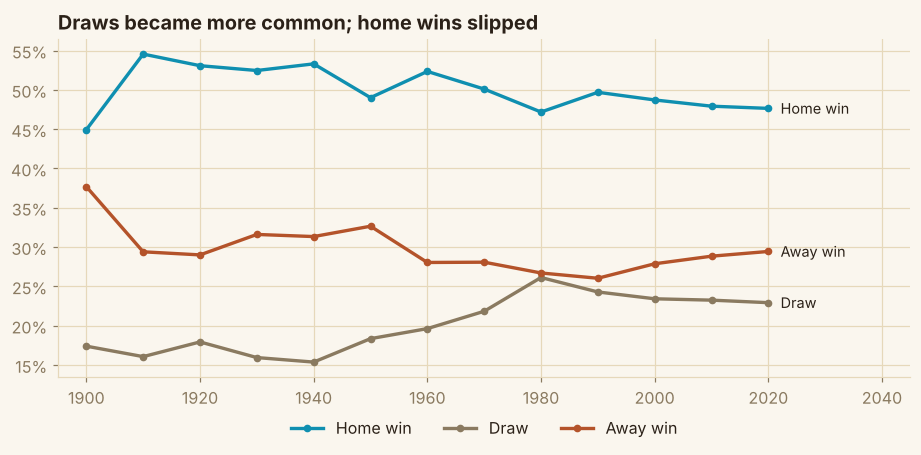

In [5]:
shares = df.groupby("decade")["result"].value_counts(normalize=True).unstack().reindex(columns=CLASSES) * 100
shares = shares[shares.index >= 1900]

fig, ax = plt.subplots(figsize=(10, 4))
for c in CLASSES:
    ax.plot(shares.index, shares[c], color=OUTCOME_COLORS[c], lw=2.2, marker="o", ms=4, label=LABELS[c])
    ax.annotate(LABELS[c], (shares.index[-1], shares[c].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9.5)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.set_xlim(1895, 2045)
ax.set_title("Draws became more common; home wins slipped")
ax.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.22))
show(fig, "p02_outcomes_by_decade")

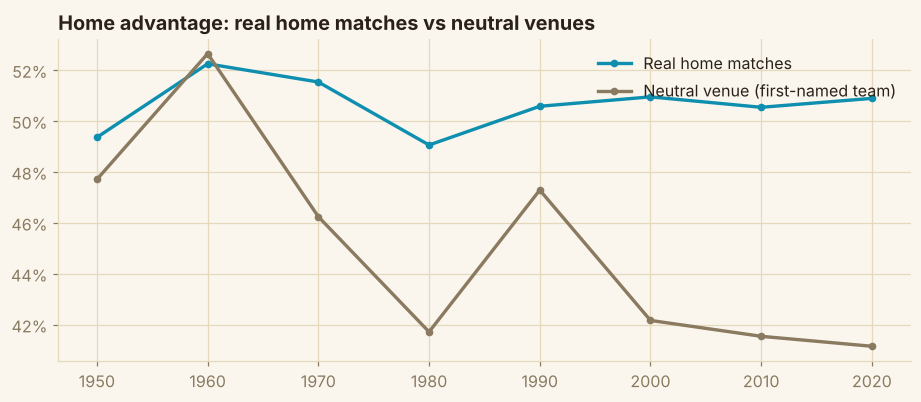

Since 2000: home win share 50.8% at real home venues vs 41.6% at neutral venues (same teams listed first).


In [6]:
home_win = (df.assign(home_won=df["result"].eq("H"))
              .groupby(["decade", "neutral"])["home_won"].mean().unstack() * 100)
home_win = home_win[home_win.index >= 1950]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(home_win.index, home_win[False], color=TEAL, lw=2.2, marker="o", ms=4, label="Real home matches")
ax.plot(home_win.index, home_win[True], color=MUTED, lw=2.2, marker="o", ms=4, label="Neutral venue (first-named team)")
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title("Home advantage: real home matches vs neutral venues")
ax.legend(loc="upper right")
show(fig, "p03_home_advantage")

adv = home_win.loc[home_win.index >= 2000].mean()
print(f"Since 2000: home win share {adv[False]:.1f}% at real home venues vs {adv[True]:.1f}% at neutral venues (same teams listed first).")

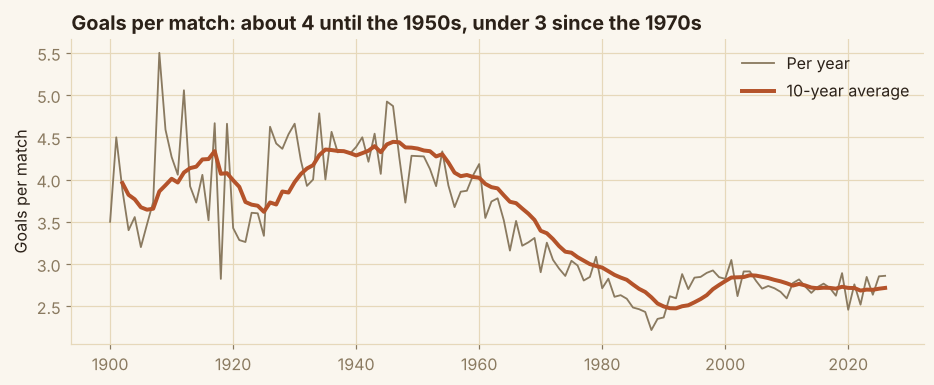

In [7]:
goals_year = df.assign(goals=df["home_score"] + df["away_score"]).groupby("year")["goals"].mean()
goals_year = goals_year[goals_year.index >= 1900]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(goals_year.index, goals_year.values, color=MUTED, lw=1.2, label="Per year")
ax.plot(goals_year.index, goals_year.rolling(10, min_periods=3).mean(), color=TERRA, lw=2.6, label="10-year average")
ax.set_ylabel("Goals per match")
ax.set_title("Goals per match: about 4 until the 1950s, under 3 since the 1970s")
ax.legend(loc="upper right")
show(fig, "p04_goals_per_match")

## 4. Metrics: what we measure and what must be beaten

Any model must beat simple rules, otherwise it adds nothing. The baselines (class frequencies, "always home win") are computed later on the **test period only**, because the share of home wins changes over time: 49% over all history, lower today. Comparing against the all-history number would be unfair to the model.

In [8]:
def outcome_index(y):
    return pd.Series(np.asarray(y)).map({c: i for i, c in enumerate(CLASSES)}).to_numpy()

def metrics(y, P):
    """Accuracy, log loss, multiclass Brier and Ranked Probability Score (lower = better, except accuracy)."""
    P = np.clip(np.asarray(P, float), 1e-12, 1)
    P = P / P.sum(axis=1, keepdims=True)
    idx = outcome_index(y)
    O = np.eye(3)[idx]
    return {
        "accuracy": float((P.argmax(1) == idx).mean()),
        "log_loss": float(-np.log(P[np.arange(len(idx)), idx]).mean()),
        "brier": float(((P - O) ** 2).sum(1).mean()),
        "rps": float((((np.cumsum(P, 1) - np.cumsum(O, 1))[:, :2]) ** 2).sum(1).mean() / 2),
    }

print("Metrics used")
print(" - accuracy: share of matches where the most likely outcome happened")
print(" - log loss: punishes confident wrong probabilities (the main metric)")
print(" - Brier   : squared error of the probabilities")
print(" - RPS     : like Brier, but knows Home < Draw < Away is an ordered scale (standard in football forecasting)")

Metrics used
 - accuracy: share of matches where the most likely outcome happened
 - log loss: punishes confident wrong probabilities (the main metric)
 - Brier   : squared error of the probabilities
 - RPS     : like Brier, but knows Home < Draw < Away is an ordered scale (standard in football forecasting)


## 5. Elo ratings

Elo gives every team one number for strength, updated after each match: beat a strong team and you gain a lot, beat a weak one and you gain little. The rating **before** each match is the feature, so it only contains information available at kick-off.

This notebook builds two versions:

| Version | K (update speed) | Goal difference | Home advantage |
|---|---|---|---|
| **Basic** | constant 32 | ignored | +100 |
| **Advanced** (inspired by eloratings.net) | by tournament importance: World Cup 60, continental finals 50, qualifiers and Nations League 40, other tournaments 30, friendlies 20 | bigger wins move ratings more | tuned on validation |

Matches played on the same date are handled as a batch: all pre-match ratings are read first, then all updates are applied. That way one match can never leak into another match of the same day.

In [9]:
CONTINENTAL_FINALS = ("UEFA Euro", "Copa América", "African Cup of Nations", "AFC Asian Cup", "Gold Cup",
                      "CONCACAF Championship", "Confederations Cup", "Oceania Nations Cup", "Gulf Cup", "Arab Cup")

def tournament_k(name):
    """Base K factor by importance of the tournament."""
    if name == "FIFA World Cup":
        return 60
    if "qualification" in name:
        return 40
    if name in ("UEFA Nations League", "CONCACAF Nations League"):
        return 40
    if name == "Friendly":
        return 20
    if name in CONTINENTAL_FINALS:
        return 50
    return 30

df["k_base"] = df["tournament"].map(tournament_k)
IMPORTANCE = {20: 1, 30: 2, 40: 3, 50: 4, 60: 5}
df["importance"] = df["k_base"].map(IMPORTANCE)
print(df["k_base"].value_counts().sort_index().rename("matches per K level").to_frame())

        matches per K level
k_base                     
20                    18263
30                     9378
40                    17245
50                     3991
60                     1068


In [10]:
def run_elo(d, k_scale=1.0, home_adv=100.0, use_tournament=True, use_goal_diff=True, base=1500.0):
    """Walk through matches in date order. Returns pre-match ratings (home, away) and the final rating of every team."""
    n = len(d)
    ratings = {}
    pre_h, pre_a = np.empty(n), np.empty(n)
    home, away = d["home_team"].to_numpy(), d["away_team"].to_numpy()
    hs, as_ = d["home_score"].to_numpy(), d["away_score"].to_numpy()
    neutral = d["neutral"].to_numpy()
    dates = d["date"].to_numpy()
    k_arr = (d["k_base"].to_numpy() if use_tournament else np.full(n, 32.0)) * k_scale

    pending, current_date = [], None
    for i in range(n):
        if dates[i] != current_date:                      # new day: apply yesterday's updates first
            for team, delta in pending:
                ratings[team] = ratings.get(team, base) + delta
            pending, current_date = [], dates[i]
        rh, ra = ratings.get(home[i], base), ratings.get(away[i], base)
        pre_h[i], pre_a[i] = rh, ra

        adv = 0.0 if neutral[i] else home_adv
        expected_home = 1.0 / (1.0 + 10 ** (-(rh + adv - ra) / 400.0))
        actual_home = 1.0 if hs[i] > as_[i] else (0.5 if hs[i] == as_[i] else 0.0)

        gd = abs(hs[i] - as_[i])
        g = 1.0
        if use_goal_diff:
            g = 1.0 if gd <= 1 else (1.5 if gd == 2 else (11 + gd) / 8.0)

        delta = k_arr[i] * g * (actual_home - expected_home)
        pending.append((home[i], delta)); pending.append((away[i], -delta))

    for team, delta in pending:
        ratings[team] = ratings.get(team, base) + delta
    return pre_h, pre_a, ratings

# Basic Elo (constant K, no goal difference): the version most tutorials use
b_h, b_a, _ = run_elo(df, use_tournament=False, use_goal_diff=False, home_adv=100)
df["elo_basic_diff"] = b_h - b_a

# sanity checks: first appearance of every team starts at 1500; ratings are zero-sum around 1500
pre_h, pre_a, final_ratings = run_elo(df)
first_seen = pd.concat([df[["match_id", "home_team"]].rename(columns={"home_team": "t"}).assign(r=pre_h),
                        df[["match_id", "away_team"]].rename(columns={"away_team": "t"}).assign(r=pre_a)]).sort_values("match_id").drop_duplicates("t")
print(f"Teams starting at exactly 1500: {(first_seen['r'] == 1500).all()}")
print(f"Mean final rating: {np.mean(list(final_ratings.values())):.1f}  (stays near 1500 because every update is zero-sum)")

Teams starting at exactly 1500: True
Mean final rating: 1500.0  (stays near 1500 because every update is zero-sum)


### 5.1 Tuning Elo (validation period only)

Two Elo settings are not obvious: how fast ratings move (`k_scale`) and the size of home advantage. They are chosen by **validation log loss** of a tiny model that uses only the Elo difference and the neutral-venue flag. The test period is not touched.

In [11]:
# Small helper model: multinomial logistic regression on [elo_diff, neutral]
def elo_only_logloss(elo_diff, neutral, y, train_mask, valid_mask):
    X = np.column_stack([elo_diff, neutral.astype(int)])
    lr = LogisticRegression(max_iter=1000).fit(X[train_mask], y[train_mask])
    P = lr.predict_proba(X[valid_mask])[:, [list(lr.classes_).index(c) for c in CLASSES]]
    return metrics(y[valid_mask], P)["log_loss"]

y_all = df["result"].to_numpy()
train_mask = ((df["date"] >= TRAIN_START) & (df["date"] < VALID_START)).to_numpy()
valid_mask = ((df["date"] >= VALID_START) & (df["date"] < TEST_START)).to_numpy()

rows = []
K_GRID, HA_GRID = (0.5, 0.7, 1.0, 1.4), (40, 60, 80, 100)
for k_scale in K_GRID:
    for home_adv in HA_GRID:
        h, a, _ = run_elo(df, k_scale=k_scale, home_adv=home_adv)
        rows.append({"k_scale": k_scale, "home_adv": home_adv,
                     "valid_log_loss": elo_only_logloss(h - a, df["neutral"].to_numpy(), y_all, train_mask, valid_mask)})
grid = pd.DataFrame(rows).sort_values("valid_log_loss").reset_index(drop=True)
BEST_K, BEST_HA = grid.loc[0, ["k_scale", "home_adv"]]
print(grid.to_string(index=False))
print(f"\nChosen on validation: k_scale={BEST_K}, home_adv={BEST_HA:.0f}")
edge = BEST_K in (K_GRID[0], K_GRID[-1]) or BEST_HA in (HA_GRID[0], HA_GRID[-1])
spread = grid["valid_log_loss"].max() - grid["valid_log_loss"].min()
print(f"Spread between best and worst setting: {spread:.4f} log loss, so Elo is not very sensitive to these two settings.")
if edge:
    print("The best setting sits on the edge of the grid; a wider grid might shift it slightly, but the gain would be tiny.")

 k_scale  home_adv  valid_log_loss
  0.7000        40          0.8582
  0.7000        60          0.8586
  1.0000        40          0.8588
  0.7000        80          0.8591
  1.0000        60          0.8591
  1.0000        80          0.8595
  0.7000       100          0.8597
  1.0000       100          0.8600
  0.5000        40          0.8603
  0.5000        60          0.8607
  0.5000        80          0.8613
  1.4000        40          0.8618
  1.4000        60          0.8620
  0.5000       100          0.8621
  1.4000        80          0.8624
  1.4000       100          0.8627

Chosen on validation: k_scale=0.7, home_adv=40
Spread between best and worst setting: 0.0045 log loss, so Elo is not very sensitive to these two settings.
The best setting sits on the edge of the grid; a wider grid might shift it slightly, but the gain would be tiny.


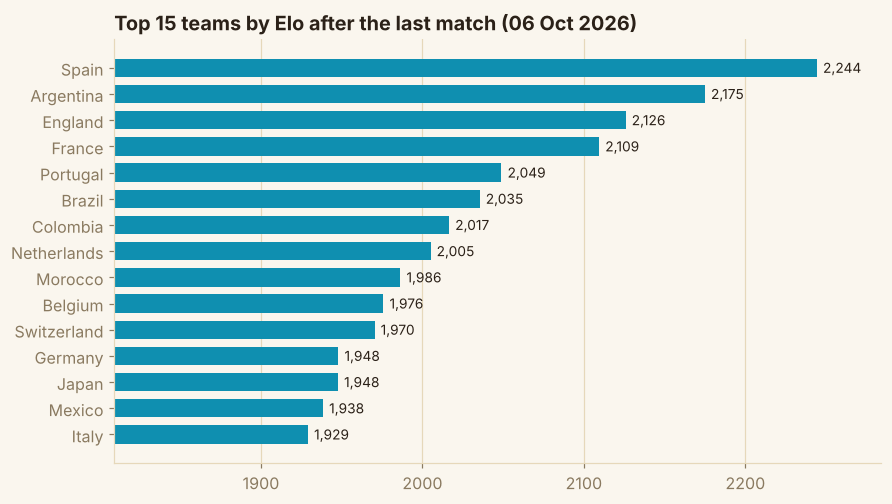

In [12]:
elo_h, elo_a, final_ratings = run_elo(df, k_scale=BEST_K, home_adv=BEST_HA)
df["elo_h"], df["elo_a"] = elo_h, elo_a

# Elo of the home/away team before each match is now stored. Top teams today and a few trajectories:
top = pd.Series(final_ratings).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index[::-1], top.values[::-1], color=TEAL, height=0.7)
for y, v in enumerate(top.values[::-1]):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(top.min() - 120, top.max() + 40)
ax.set_title(f"Top 15 teams by Elo after the last match ({df['date'].max():%d %b %Y})")
ax.grid(axis="y", visible=False)
show(fig, "p05_top_elo")

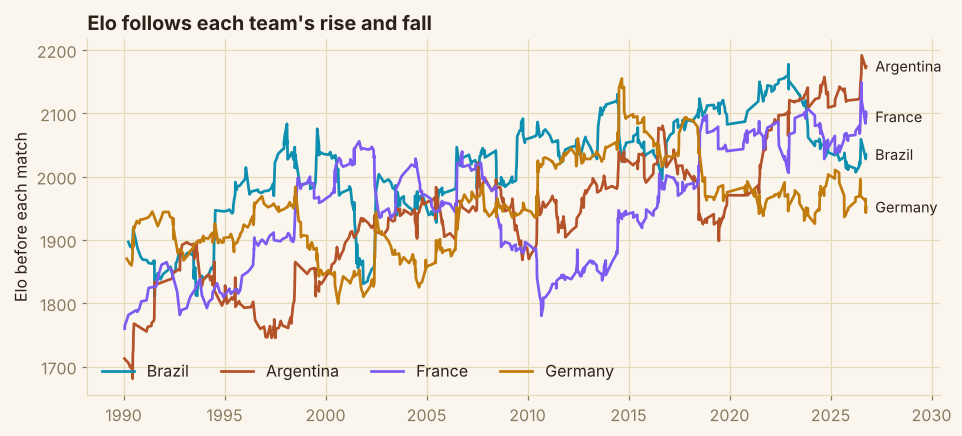

In [13]:
team_rows = pd.concat([df[["date", "home_team", "elo_h"]].set_axis(["date", "team", "elo"], axis=1),
                       df[["date", "away_team", "elo_a"]].set_axis(["date", "team", "elo"], axis=1)])
show_teams = [("Brazil", TEAL), ("Argentina", TERRA), ("France", PURPLE), ("Germany", AMBER)]

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in show_teams:
    t = team_rows[(team_rows["team"] == name) & (team_rows["date"] >= "1990-01-01")].sort_values("date")
    ax.plot(t["date"], t["elo"], color=color, lw=1.8, label=name)
    ax.annotate(name, (t["date"].iloc[-1], t["elo"].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9.5)
ax.set_xlim(right=pd.Timestamp("2030-06-01"))
ax.set_ylabel("Elo before each match")
ax.set_title("Elo follows each team's rise and fall")
ax.legend(loc="lower left", ncol=4)
show(fig, "p06_elo_trajectories")

## 6. Form features (leak-free)

For each team and match we compute averages over its **previous** 5 and 10 matches (points, goals scored, goals conceded, goal difference), days since its last match, and how many matches it has played so far.

Two design decisions:

- **A "long" table keyed by `match_id`.** Every match becomes two rows (one per team). Features are merged back by `(match_id, team)`, which is unique, so no match can be duplicated by the merge.
- **Strictly earlier dates.** If a team plays twice on one date, both matches use only information from before that date.

All windows use the same statistic (the **mean**) so the columns are on comparable scales.

In [14]:
STATS = ["pts_l5", "gf_l5", "ga_l5", "gd_l5", "pts_l10", "gf_l10", "ga_l10", "gd_l10", "rest_days", "n_prior"]

def build_long(d):
    side = lambda t, o, gf, ga: pd.DataFrame({"match_id": d["match_id"], "date": d["date"], "team": d[t], "opp": d[o], "gf": d[gf], "ga": d[ga]})
    long = pd.concat([side("home_team", "away_team", "home_score", "away_score"),
                      side("away_team", "home_team", "away_score", "home_score")], ignore_index=True)
    long["pts"] = np.select([long["gf"] > long["ga"], long["gf"] == long["ga"]], [3, 1], 0)
    long["gd"] = long["gf"] - long["ga"]
    return long.sort_values(["team", "date", "match_id"], kind="stable").reset_index(drop=True)

long = build_long(df)
grp = long.groupby("team", sort=False)
for w in (5, 10):
    for col in ("pts", "gf", "ga", "gd"):
        long[f"{col}_l{w}"] = grp[col].transform(lambda s, w=w: s.shift(1).rolling(w, min_periods=3).mean())
long["rest_days"] = grp["date"].diff().dt.days.clip(upper=365)
long["n_prior"] = grp.cumcount()

# same-day fix: every match of a team on one date gets the features of the FIRST of them
long[STATS] = long.groupby(["team", "date"], sort=False)[STATS].transform("first")

def attach(d, long, prefix, team_col):
    cols = long[["match_id", "team"] + STATS].rename(columns={s: f"{prefix}_{s}" for s in STATS})
    out = d.merge(cols, left_on=["match_id", team_col], right_on=["match_id", "team"], how="left").drop(columns="team")
    assert len(out) == len(d), "merge changed the number of rows"
    return out

wide = attach(attach(df, long, "h", "home_team"), long, "a", "away_team")
print(f"Rows before/after merging features: {len(df):,} -> {len(wide):,}")
wide[["date", "home_team", "away_team", "h_pts_l5", "h_gf_l5", "h_rest_days", "elo_h"]].tail(5)

Rows before/after merging features: 49,945 -> 49,945


,date,home_team,away_team,h_pts_l5,h_gf_l5,h_rest_days,elo_h
49940,2026-10-06,Belize,French Guiana,0.6000,0.8000,3.0000,"1,291.7398"
49941,2026-10-06,Turks and Caicos Islands,Montserrat,2.0000,2.0000,2.0000,"1,098.6009"
49942,2026-10-06,Antigua and Barbuda,Aruba,1.4000,1.8000,5.0000,"1,187.8238"
49943,2026-10-06,Saint Martin,Bahamas,2.4000,3.8000,5.0000,"1,293.1126"
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2.2000,1.2000,3.0000,"1,728.2673"


In [15]:
# UNIT TEST: recompute 300 random feature values by hand from raw data, using only strictly earlier matches
rng = np.random.default_rng(SEED)
sample = wide[(wide["h_n_prior"] >= 5)].sample(300, random_state=SEED)
bad = 0
for r in sample.itertuples():
    prev = long[(long["team"] == r.home_team) & (long["date"] < r.date)].tail(5)
    manual = prev["pts"].mean()
    bad += int(not np.isclose(manual, r.h_pts_l5))
print(f"Hand-recomputed 'points in last 5' for 300 random matches: {bad} mismatches")
print(f"First match of every team has no form yet (NaN): {wide.loc[wide['h_n_prior'] == 0, 'h_pts_l5'].isna().all()}")
assert bad == 0

Hand-recomputed 'points in last 5' for 300 random matches: 0 mismatches
First match of every team has no form yet (NaN): True


In [16]:
def derive(d):
    """Everything the models see. Works on the merged table and on a single hypothetical match."""
    d = d.copy()
    d["neutral_i"] = d["neutral"].astype(int)
    d["elo_diff"] = d["elo_h"] - d["elo_a"]
    d["elo_exp"] = 1 / (1 + 10 ** (-(d["elo_diff"] + np.where(d["neutral"], 0, BEST_HA)) / 400))
    for w in (5, 10):
        d[f"pts_diff_l{w}"] = d[f"h_pts_l{w}"] - d[f"a_pts_l{w}"]
        d[f"gd_diff_l{w}"] = d[f"h_gd_l{w}"] - d[f"a_gd_l{w}"]
    d["exp_gf_h"] = (d["h_gf_l10"] + d["a_ga_l10"]) / 2        # attack of home meets defence of away
    d["exp_gf_a"] = (d["a_gf_l10"] + d["h_ga_l10"]) / 2
    d["log_n_h"], d["log_n_a"] = np.log1p(d["h_n_prior"]), np.log1p(d["a_n_prior"])
    return d

data = derive(wide)

F_ELO  = ["elo_diff", "neutral_i"]
F_FORM = ["h_pts_l5", "a_pts_l5", "h_gf_l5", "a_gf_l5", "h_ga_l5", "a_ga_l5"]     # the "form only" idea
F_ALL  = (F_ELO + ["elo_h", "elo_a", "elo_exp", "importance"]
          + [f"{k}_{s}" for k in ("h", "a") for s in STATS if s != "n_prior"]
          + ["pts_diff_l5", "gd_diff_l5", "pts_diff_l10", "gd_diff_l10", "exp_gf_h", "exp_gf_a", "log_n_h", "log_n_a"])
print(f"{len(F_ALL)} features in the full set; {len(F_ELO)} Elo-only; {len(F_FORM)} form-only")

32 features in the full set; 2 Elo-only; 6 form-only


## 7. Train / validation / test split

The split is **by time**, never random:

| Period | Matches | Used for |
|---|---|---|
| 1990 → 2018 | train | fit models |
| 2019 → 2022 | validation | choose settings (Elo, hyper-parameters) |
| **2023 → Oct 2026** | **test** | final score, looked at once (includes the 2026 World Cup) |

After the settings are chosen, models are refit on train + validation and scored on the test period. A random split would let the model see the future and give inflated scores.

In [17]:
model_data = data[data["date"] >= TRAIN_START].copy()
tr = model_data[model_data["date"] < VALID_START]
va = model_data[(model_data["date"] >= VALID_START) & (model_data["date"] < TEST_START)]
te = model_data[model_data["date"] >= TEST_START]
trva = pd.concat([tr, va])

split_table = pd.DataFrame({
    "matches": [len(tr), len(va), len(te)],
    "from": [tr["date"].min(), va["date"].min(), te["date"].min()],
    "to": [tr["date"].max(), va["date"].max(), te["date"].max()],
    "home win %": [x["result"].eq("H").mean() * 100 for x in (tr, va, te)],
    "draw %": [x["result"].eq("D").mean() * 100 for x in (tr, va, te)],
    "away win %": [x["result"].eq("A").mean() * 100 for x in (tr, va, te)],
}, index=["train", "validation", "test"])
split_table

,matches,from,to,home win %,draw %,away win %
train,25126,1990-01-12,2018-12-31,48.6508,23.7005,27.6487
validation,3597,2019-01-02,2022-12-30,48.5961,22.4910,28.9130
test,4098,2023-01-02,2026-10-06,47.2182,22.7672,30.0146


In [18]:
# Baselines on the TEST period
prior = tr["result"].value_counts(normalize=True).reindex(CLASSES).to_numpy()
P_prior_te = np.tile(prior, (len(te), 1))
m_prior = metrics(te["result"], P_prior_te)

always_home = te["result"].eq("H").mean()
elo_rule = (np.where(te["elo_diff"] + np.where(te["neutral"], 0, BEST_HA) > 0, "H", "A") == te["result"]).mean()

print(f"Always predict home win     : accuracy {always_home * 100:.2f}%   <- the fair accuracy to beat")
print(f"Stronger Elo team wins      : accuracy {elo_rule * 100:.2f}%   (never predicts draws)")
print(f"Class frequencies (prior)   : log loss {m_prior['log_loss']:.4f}   <- the log loss to beat")
print(f"Standard error of an accuracy on {len(te):,} matches: about ±{np.sqrt(0.5 * 0.5 / len(te)) * 100:.1f} points")

Always predict home win     : accuracy 47.22%   <- the fair accuracy to beat
Stronger Elo team wins      : accuracy 60.37%   (never predicts draws)
Class frequencies (prior)   : log loss 1.0538   <- the log loss to beat
Standard error of an accuracy on 4,098 matches: about ±0.8 points


## 8. Models and tuning

| Model | Features | Idea |
|---|---|---|
| **Prior** (baseline) | none | always the class frequencies of the training period |
| **RF, form only** | 6 form columns | the "form alone" idea: random forest on recent results |
| **LR, Elo only** | Elo difference + neutral flag | logistic regression, the simplest strong model |
| **LR, all features** | all 32 | regularised logistic regression |
| **Random Forest** | all 32 | many decision trees, averaged |
| **Gradient Boosting** | all 32 | trees built one after another, each fixing the last one's errors |
| **Poisson goals** | all 32 | predicts the expected goals of each team, then converts the scoreline distribution into home / draw / away |
| **Ensemble** | all of the above except Prior and form-only | equal-weight average of the probabilities, fixed in advance |

Every model outputs **probabilities** for home win, draw and away win. Small hyper-parameter grids are tuned on the validation period only.

In [19]:
def to_classes(model, P):
    """Reorder predict_proba columns into H, D, A."""
    return P[:, [list(model.classes_).index(c) for c in CLASSES]]

class ClassifierModel:
    def __init__(self, name, make, feats):
        self.name, self.make, self.feats = name, make, feats
    def fit(self, d):
        self.m = self.make().fit(d[self.feats], d["result"]); return self
    def proba(self, d):
        return to_classes(self.m, self.m.predict_proba(d[self.feats]))

class PoissonGoals:
    """Two Poisson regressions (home goals, away goals) -> scoreline grid -> H/D/A probabilities."""
    def __init__(self, name, feats, alpha=1.0, max_goals=10):
        self.name, self.feats, self.alpha, self.G = name, feats, alpha, max_goals
    def _pipe(self):
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PoissonRegressor(alpha=self.alpha, max_iter=1000))
    def fit(self, d):
        self.mh = self._pipe().fit(d[self.feats], d["home_score"])
        self.ma = self._pipe().fit(d[self.feats], d["away_score"]); return self
    def expected_goals(self, d):
        return self.mh.predict(d[self.feats]), self.ma.predict(d[self.feats])
    def proba(self, d):
        lh, la = self.expected_goals(d)
        k = np.arange(self.G + 1)
        joint = poisson.pmf(k[None, :, None], lh[:, None, None]) * poisson.pmf(k[None, None, :], la[:, None, None])
        i, j = np.indices((self.G + 1, self.G + 1))
        P = np.column_stack([(joint * (i > j)).sum((1, 2)), (joint * (i == j)).sum((1, 2)), (joint * (i < j)).sum((1, 2))])
        return P / P.sum(1, keepdims=True)

def rf(leaf):  return lambda: make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, n_jobs=-1, random_state=SEED))
def lr(C):     return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=C, max_iter=2000))
def hgb(depth, iters): return lambda: HistGradientBoostingClassifier(max_depth=depth, max_iter=iters, learning_rate=0.05, l2_regularization=1.0, early_stopping=False, random_state=SEED)

In [20]:
# ---- tuning on VALIDATION (models are fit on train only) ----
def val_score(model):
    return metrics(va["result"], model.fit(tr).proba(va))["log_loss"]

search = {
    "LR, all features":   [(f"C={C}", lambda C=C: ClassifierModel("LR, all features", lr(C), F_ALL)) for C in (0.01, 0.1, 1.0)],
    "Random Forest":      [(f"min_leaf={l}", lambda l=l: ClassifierModel("Random Forest", rf(l), F_ALL)) for l in (20, 50, 100)],
    "Gradient Boosting":  [(f"depth={d}, iters={n}", lambda d=d, n=n: ClassifierModel("Gradient Boosting", hgb(d, n), F_ALL)) for d in (2, 3) for n in (100, 250)],
    "Poisson goals":      [(f"alpha={a}", lambda a=a: PoissonGoals("Poisson goals", F_ALL, alpha=a)) for a in (0.1, 1.0, 10.0)],
}
best_factory, tuning_rows = {}, []
for name, options in search.items():
    scores = [(label, val_score(make()), make) for label, make in options]
    label, score, make = min(scores, key=lambda t: t[1])
    best_factory[name] = make
    tuning_rows += [{"model": name, "setting": l, "valid_log_loss": s, "chosen": l == label} for l, s, _ in scores]

pd.DataFrame(tuning_rows)

,model,setting,valid_log_loss,chosen
0,"LR, all features",C=0.01,0.8543,False
1,"LR, all features",C=0.1,0.8531,False
2,"LR, all features",C=1.0,0.8529,True
3,Random Forest,min_leaf=20,0.8608,True
4,Random Forest,min_leaf=50,0.8614,False
5,Random Forest,min_leaf=100,0.8636,False
6,Gradient Boosting,"depth=2, iters=100",0.8563,True
7,Gradient Boosting,"depth=2, iters=250",0.8580,False
8,Gradient Boosting,"depth=3, iters=100",0.8568,False
9,Gradient Boosting,"depth=3, iters=250",0.8597,False


In [21]:
# ---- final model list: fixed settings for the simple ones, tuned settings for the rest ----
def make_models():
    return {
        "RF, form only":     ClassifierModel("RF, form only", rf(50), F_FORM),
        "LR, Elo only":      ClassifierModel("LR, Elo only", lr(1.0), F_ELO),
        "LR, all features":  best_factory["LR, all features"](),
        "Random Forest":     best_factory["Random Forest"](),
        "Gradient Boosting": best_factory["Gradient Boosting"](),
        "Poisson goals":     best_factory["Poisson goals"](),
    }

ENSEMBLE_PARTS = ["LR, Elo only", "LR, all features", "Random Forest", "Gradient Boosting", "Poisson goals"]

def predict_all(models, d):
    P = {name: m.proba(d) for name, m in models.items()}
    P["Ensemble"] = np.mean([P[n] for n in ENSEMBLE_PARTS], axis=0)
    return P

# validation view (train-only fits), then refit on train + validation for the test
models_val = {k: m.fit(tr) for k, m in make_models().items()}
P_va = predict_all(models_val, va)
P_va["Prior"] = np.tile(prior, (len(va), 1))
val_table = pd.DataFrame({k: metrics(va["result"], P) for k, P in P_va.items()}).T.sort_values("log_loss")
print("VALIDATION results (models fit on train only)")
val_table

VALIDATION results (models fit on train only)


,accuracy,log_loss,brier,rps
"LR, all features",0.6083,0.8529,0.5000,0.1661
Ensemble,0.6116,0.8532,0.4999,0.1661
Poisson goals,0.6094,0.8543,0.5007,0.1666
Gradient Boosting,0.6127,0.8563,0.5013,0.1667
"LR, Elo only",0.6097,0.8582,0.5032,0.1671
Random Forest,0.6080,0.8608,0.5041,0.1679
"RF, form only",0.5399,0.9732,0.5779,0.2029
Prior,0.4860,1.0456,0.6300,0.2277


## 9. Test results

Models are refit on **train + validation** and scored once on the test period (2023 → Oct 2026). Results are shown for the whole period and for subsets that matter:

- **Competitive matches** (everything except friendlies)
- **Balanced matches** (|Elo difference| ≤ 200): no heavy favourite, so the model has to work harder
- **World Cup 2026** (104 matches, played June–July 2026)

In [22]:
models_te = {k: m.fit(trva) for k, m in make_models().items()}
P_te = predict_all(models_te, te)
P_te["Prior"] = P_prior_te
ORDER = ["Prior", "RF, form only", "LR, Elo only", "LR, all features", "Random Forest", "Gradient Boosting", "Poisson goals", "Ensemble"]

subsets = {
    "All test matches": np.ones(len(te), bool),
    "Competitive only": (te["tournament"] != "Friendly").to_numpy(),
    "Balanced (|Elo diff| <= 200)": (te["elo_diff"].abs() <= 200).to_numpy(),
    "World Cup 2026": ((te["tournament"] == "FIFA World Cup") & (te["date"] >= "2026-01-01")).to_numpy(),
}
def table_for(mask):
    return pd.DataFrame({k: metrics(te["result"][mask], P_te[k][mask]) for k in ORDER}).T

results = {name: table_for(mask) for name, mask in subsets.items()}
for name, mask in subsets.items():
    print(f"\n{name}  ({int(mask.sum()):,} matches)")
    print(results[name].round(4).to_string())


All test matches  (4,098 matches)
                   accuracy  log_loss  brier    rps
Prior                0.4722    1.0538 0.6360 0.2300
RF, form only        0.5303    0.9825 0.5854 0.2057
LR, Elo only         0.6074    0.8705 0.5118 0.1704
LR, all features     0.6086    0.8606 0.5055 0.1683
Random Forest        0.6086    0.8670 0.5092 0.1696
Gradient Boosting    0.6083    0.8643 0.5075 0.1690
Poisson goals        0.6076    0.8624 0.5061 0.1683
Ensemble             0.6093    0.8617 0.5062 0.1684

Competitive only  (3,118 matches)
                   accuracy  log_loss  brier    rps
Prior                0.4631    1.0577 0.6392 0.2337
RF, form only        0.5318    0.9757 0.5806 0.2058
LR, Elo only         0.6164    0.8580 0.5033 0.1683
LR, all features     0.6216    0.8481 0.4971 0.1664
Random Forest        0.6183    0.8518 0.4992 0.1671
Gradient Boosting    0.6187    0.8509 0.4987 0.1669
Poisson goals        0.6190    0.8498 0.4977 0.1664
Ensemble             0.6203    0.8487 0.4974 0

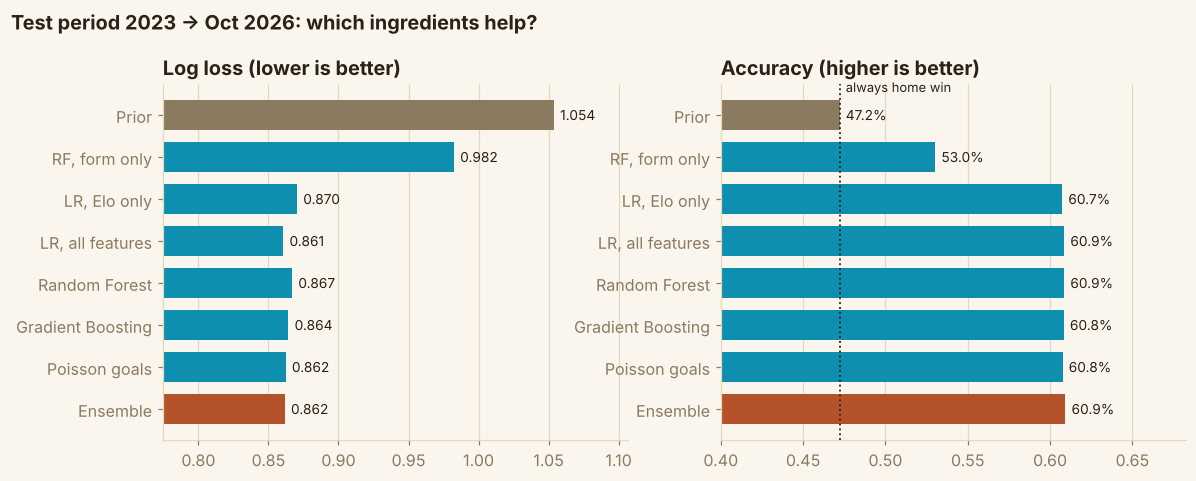

In [23]:
all_res = results["All test matches"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title in zip(axes, ["log_loss", "accuracy"], ["Log loss (lower is better)", "Accuracy (higher is better)"]):
    vals = all_res[col].reindex(ORDER)
    colors = [TERRA if n == "Ensemble" else (MUTED if n == "Prior" else TEAL) for n in ORDER]
    bars = ax.barh(ORDER[::-1], vals.values[::-1], color=colors[::-1], height=0.7)
    for p in bars:
        txt = f"{p.get_width():.3f}" if col == "log_loss" else f"{p.get_width() * 100:.1f}%"
        ax.annotate(txt, (p.get_width(), p.get_y() + p.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    lo = vals.min() * 0.9 if col == "log_loss" else 0.4
    ax.set_xlim(lo, vals.max() * (1.05 if col == "log_loss" else 1.12))
    ax.set_title(title); ax.grid(axis="y", visible=False)
    if col == "accuracy":
        ax.axvline(always_home, color=INK, ls=":", lw=1.2)
        ax.annotate("always home win", (always_home, 7.55), xytext=(4, 0), textcoords="offset points", fontsize=8.5, color=INK)
fig.suptitle("Test period 2023 → Oct 2026: which ingredients help?", x=0.01, y=1.04, ha="left", fontweight="bold", fontsize=13)
show(fig, "p07_model_comparison")

## 10. Is the improvement real?

With about 4,000 test matches, small differences can be luck. A **paired bootstrap** resamples the matches 2,000 times and recomputes the difference in log loss between two models on the same matches. If the 95% range excludes 0, the difference is unlikely to be luck. (Matches inside one tournament are not fully independent, so treat the ranges as slightly optimistic.)

In [24]:
def per_match_logloss(P, y):
    idx = outcome_index(y)
    return -np.log(np.clip(P[np.arange(len(idx)), idx], 1e-12, 1))

def paired_bootstrap(a, b, n_boot=2000, seed=SEED):
    """Mean difference a - b of per-match log loss (negative = a is better) and its 95% range."""
    d = per_match_logloss(P_te[a], te["result"]) - per_match_logloss(P_te[b], te["result"])
    rng = np.random.default_rng(seed)
    means = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
    return d.mean(), *np.percentile(means, [2.5, 97.5])

pairs = [("LR, Elo only", "Prior"), ("RF, form only", "Prior"),
         ("LR, all features", "LR, Elo only"), ("Random Forest", "LR, Elo only"),
         ("Gradient Boosting", "LR, Elo only"), ("Poisson goals", "LR, Elo only"), ("Ensemble", "LR, Elo only")]
rows = []
for a, b in pairs:
    mean, lo, hi = paired_bootstrap(a, b)
    verdict = "better" if hi < 0 else ("worse" if lo > 0 else "no clear difference")
    rows.append({"model A": a, "vs model B": b, "log loss A - B": mean, "95% low": lo, "95% high": hi, "verdict": verdict})
boot = pd.DataFrame(rows)
boot

,model A,vs model B,log loss A - B,95% low,95% high,verdict
0,"LR, Elo only",Prior,-0.1834,-0.1994,-0.1676,better
1,"RF, form only",Prior,-0.0714,-0.0814,-0.0615,better
2,"LR, all features","LR, Elo only",-0.0098,-0.0140,-0.0057,better
3,Random Forest,"LR, Elo only",-0.0035,-0.0083,0.0012,no clear difference
4,Gradient Boosting,"LR, Elo only",-0.0062,-0.0106,-0.0020,better
5,Poisson goals,"LR, Elo only",-0.0081,-0.0122,-0.0041,better
6,Ensemble,"LR, Elo only",-0.0087,-0.0119,-0.0056,better


In [25]:
# Accuracy gain of the best simple model over the fair baseline, with its uncertainty
acc_elo = (P_te["LR, Elo only"].argmax(1) == outcome_index(te["result"])).mean()
rng = np.random.default_rng(SEED)
hit = (P_te["LR, Elo only"].argmax(1) == outcome_index(te["result"])).astype(float)
base_hit = (te["result"].to_numpy() == "H").astype(float)
boots = [(hit[i] - base_hit[i]).mean() for i in (rng.integers(0, len(te), len(te)) for _ in range(2000))]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"LR on Elo only: accuracy {acc_elo * 100:.1f}% vs {always_home * 100:.1f}% for 'always home win'")
print(f"Gain: {(acc_elo - always_home) * 100:+.1f} points  (95% range {lo * 100:+.1f} to {hi * 100:+.1f})")

LR on Elo only: accuracy 60.7% vs 47.2% for 'always home win'
Gain: +13.5 points  (95% range +12.0 to +14.9)


## 11. Calibration and errors

A good forecaster is **calibrated**: when it says "70%", the event should happen about 70% of the time. The chart groups the ensemble's predicted probabilities into 10 bins and compares them with what actually happened. Points on the diagonal are perfectly calibrated.

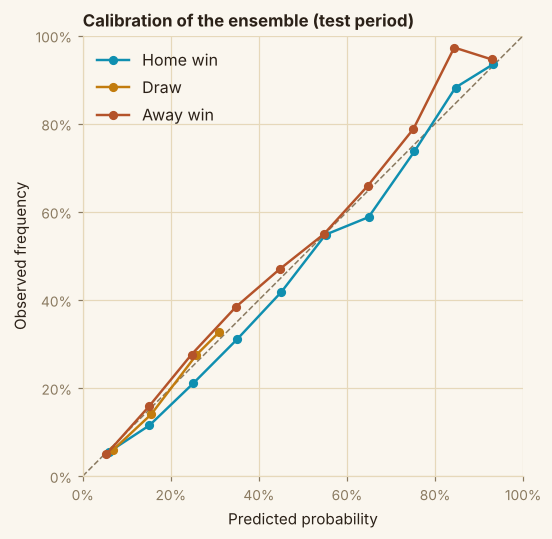

Home-win probabilities run slightly high in the middle range (the home curve sits below the diagonal); away wins slightly low.
Ensemble's highest draw probability on any test match: 34.1% (average 22.1%, actual draw rate 22.8%)


In [26]:
P_ens = P_te["Ensemble"]
y_idx = outcome_index(te["result"])
names = {0: "Home win", 1: "Draw", 2: "Away win"}
colors3 = {0: TEAL, 1: AMBER, 2: TERRA}

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
bins = np.linspace(0, 1, 11)
for k in range(3):
    p, hit = P_ens[:, k], (y_idx == k).astype(float)
    b = np.digitize(p, bins[1:-1])
    xs, ys = [], []
    for i in range(10):
        m = b == i
        if m.sum() >= 30:
            xs.append(p[m].mean()); ys.append(hit[m].mean())
    ax.plot(xs, ys, "o-", color=colors3[k], lw=1.6, ms=5, label=names[k])
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Calibration of the ensemble (test period)", fontsize=11)
ax.tick_params(labelsize=9); ax.xaxis.label.set_size(10); ax.yaxis.label.set_size(10)
ax.legend(loc="upper left")
show(fig, "p08_calibration")

draw_p = P_ens[:, 1]
print("Home-win probabilities run slightly high in the middle range (the home curve sits below the diagonal); away wins slightly low.")
print(f"Ensemble's highest draw probability on any test match: {draw_p.max():.1%} (average {draw_p.mean():.1%}, actual draw rate {(y_idx == 1).mean():.1%})")

In [27]:
pred_idx = P_ens.argmax(1)
cm = pd.crosstab(pd.Series(y_idx, name="actual").map(names), pd.Series(pred_idx, name="predicted").map(names))
cm = cm.reindex(index=list(names.values()), columns=list(names.values()), fill_value=0)
print("Confusion matrix (rows = actual, columns = predicted)")
print(cm.to_string())
recall = (cm.values.diagonal() / cm.sum(1).values)
print("\nShare of each real outcome that the model called correctly:")
for n, r in zip(names.values(), recall):
    print(f"  {n:<9}{r:6.1%}")
print("\nDraws are almost never the single most likely outcome, even though they are ~1 match in 4-5.")
print("That is normal for football models: the draw probability is useful, the draw *call* rarely is.")

Confusion matrix (rows = actual, columns = predicted)
predicted  Home win  Draw  Away win
actual                             
Home win       1720     0       215
Draw            612     0       321
Away win        452     1       777

Share of each real outcome that the model called correctly:
  Home win  88.9%
  Draw       0.0%
  Away win  63.2%

Draws are almost never the single most likely outcome, even though they are ~1 match in 4-5.
That is normal for football models: the draw probability is useful, the draw *call* rarely is.


## 12. What drives the predictions?

**Permutation importance:** shuffle one feature at a time on the test matches and see how much the log loss gets worse. A big increase means the model relied on that feature. It is measured on the Random Forest and on the regularised logistic regression, so the picture does not depend on one model type.

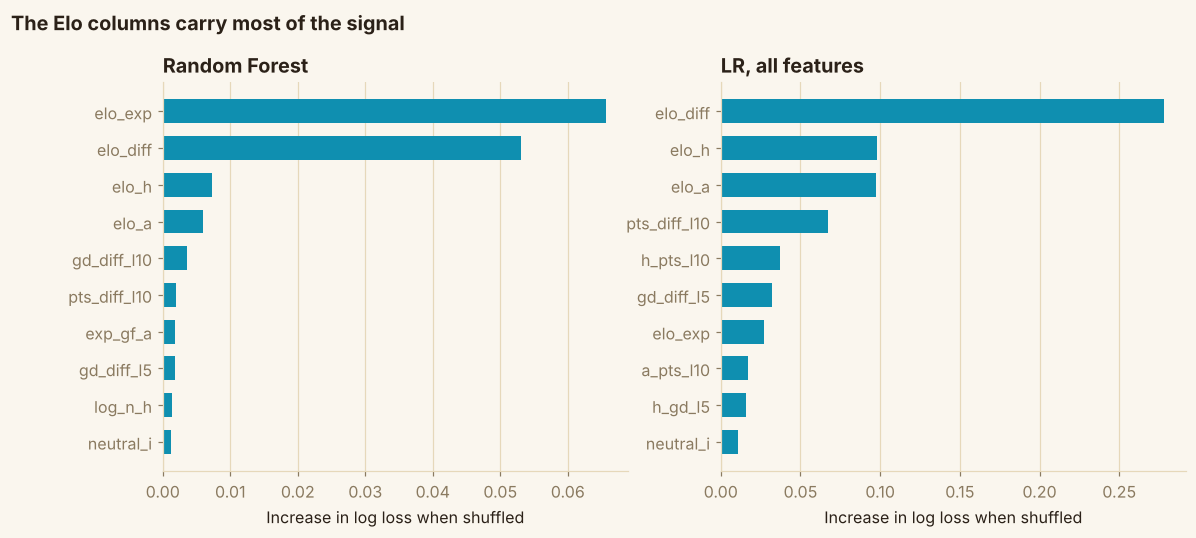

Top 5 (Random Forest): elo_exp, elo_diff, elo_h, elo_a, gd_diff_l10


In [28]:
def perm_importance(model, d, n_rep=3, seed=SEED):
    rng = np.random.default_rng(seed)
    base = metrics(d["result"], model.proba(d))["log_loss"]
    out = {}
    for f in model.feats:
        inc = []
        for _ in range(n_rep):
            d2 = d.copy(); d2[f] = rng.permutation(d2[f].to_numpy())
            inc.append(metrics(d["result"], model.proba(d2))["log_loss"] - base)
        out[f] = np.mean(inc)
    return pd.Series(out).sort_values(ascending=False)

imp = {k: perm_importance(models_te[k], te) for k in ("Random Forest", "LR, all features")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=False)
for ax, (k, s) in zip(axes, imp.items()):
    top = s.head(10)[::-1]
    ax.barh(top.index, top.values, color=TEAL, height=0.65)
    ax.set_title(k); ax.set_xlabel("Increase in log loss when shuffled"); ax.grid(axis="y", visible=False)
fig.suptitle("The Elo columns carry most of the signal", x=0.01, y=1.02, ha="left", fontweight="bold", fontsize=13)
show(fig, "p09_importance")
print("Top 5 (Random Forest):", ", ".join(imp["Random Forest"].head(5).index))

## 13. World Cup 2026 backtest

The 2026 World Cup (104 matches, 11 June → 19 July 2026) sits fully inside the test period. The models were fit on matches **before 2023** and never saw it, and each match's features use only information from before that match. That makes it a proper out-of-sample check.

In [29]:
wc_mask = subsets["World Cup 2026"]
wc = te[wc_mask].copy()
Pw = P_te["Ensemble"][wc_mask]
wc["p_home"], wc["p_draw"], wc["p_away"] = Pw[:, 0], Pw[:, 1], Pw[:, 2]
wc["pred"] = np.array(CLASSES)[Pw.argmax(1)]
wc["p_actual"] = Pw[np.arange(len(wc)), outcome_index(wc["result"])]
wc["correct"] = wc["pred"] == wc["result"]

print(f"World Cup 2026: {len(wc)} matches, ensemble accuracy {wc['correct'].mean():.1%} (always-home baseline {(wc['result'] == 'H').mean():.1%})")
by_out = wc.groupby("result")["correct"].agg(["mean", "size"]).rename(columns={"mean": "called correctly", "size": "matches"})
print(by_out.rename(index={"H": "Home win", "D": "Draw", "A": "Away win"}).round(3).to_string())

cols = ["date", "home_team", "away_team", "home_score", "away_score", "p_home", "p_draw", "p_away", "p_actual"]
print("\nBiggest surprises (lowest probability given to what actually happened):")
wc.sort_values("p_actual").head(8)[cols].round(3).reset_index(drop=True)

World Cup 2026: 104 matches, ensemble accuracy 66.3% (always-home baseline 47.1%)
          called correctly  matches
result                             
Away win            0.7740       31
Draw                0.0000       24
Home win            0.9180       49

Biggest surprises (lowest probability given to what actually happened):


,date,home_team,away_team,home_score,away_score,p_home,p_draw,p_away,p_actual
0,2026-06-15,Spain,Cape Verde,0,0,0.8850,0.0870,0.0270,0.0870
1,2026-06-20,Ecuador,Curaçao,0,0,0.8230,0.1270,0.0500,0.1270
2,2026-06-23,England,Ghana,0,0,0.8190,0.1330,0.0480,0.1330
3,2026-06-12,Canada,Bosnia and Herzegovina,1,1,0.7590,0.1690,0.0720,0.1690
4,2026-06-24,South Africa,South Korea,1,0,0.1720,0.2540,0.5740,0.1720
5,2026-06-17,Portugal,DR Congo,1,1,0.7240,0.1810,0.0950,0.1810
6,2026-06-21,Uruguay,Cape Verde,2,2,0.7270,0.1810,0.0910,0.1810
7,2026-06-13,Qatar,Switzerland,1,1,0.0910,0.1830,0.7260,0.1830


In [30]:
# How trustworthy are the stated probabilities? Group World Cup matches by the model's confidence in its top pick.
wc["confidence"] = Pw.max(1)
wc["band"] = pd.cut(wc["confidence"], [0, 0.45, 0.55, 0.70, 1.0], labels=["< 45%", "45-55%", "55-70%", "> 70%"])
band = wc.groupby("band", observed=True).agg(matches=("correct", "size"), avg_confidence=("confidence", "mean"), hit_rate=("correct", "mean"))
band.round(3)

,matches,avg_confidence,hit_rate
band,,,
< 45%,24,0.4110,0.3330
45-55%,21,0.4980,0.8570
55-70%,33,0.6150,0.7270
> 70%,26,0.7730,0.7310


## 14. Predict any match

`predict_match` uses the **latest** Elo rating of each team and its form over its last 5 and 10 matches in the data, then returns probabilities from the ensemble. The models used here are the ones fit on train + validation (data up to 2022); Elo and form are current as of the last match in the file.

In [31]:
LAST_DATE = df["date"].max()
current_elo = pd.Series(final_ratings)

def team_state(team, asof):
    rows = long[(long["team"] == team) & (long["date"] < asof)].tail(10)
    if rows.empty: raise ValueError(f"No matches before {asof:%Y-%m-%d} for {team}")
    last5 = rows.tail(5)
    return {"pts_l5": last5["pts"].mean(), "gf_l5": last5["gf"].mean(), "ga_l5": last5["ga"].mean(), "gd_l5": last5["gd"].mean(),
            "pts_l10": rows["pts"].mean(), "gf_l10": rows["gf"].mean(), "ga_l10": rows["ga"].mean(), "gd_l10": rows["gd"].mean(),
            "rest_days": min((asof - rows["date"].iloc[-1]).days, 365), "n_prior": int((long["team"] == team).sum())}

def resolve(team):
    if team in current_elo.index: return team
    close = difflib.get_close_matches(team, list(current_elo.index), n=3)
    raise ValueError(f"Unknown team '{team}'. Did you mean: {close}?")

def predict_match(home, away, neutral=True, tournament="FIFA World Cup", asof=None):
    """Return home / draw / away probabilities for a hypothetical match."""
    home, away = resolve(home), resolve(away)
    asof = pd.Timestamp(asof) if asof is not None else LAST_DATE + pd.Timedelta(days=1)
    sh, sa = team_state(home, asof), team_state(away, asof)
    row = {"neutral": neutral, "elo_h": current_elo[home], "elo_a": current_elo[away],
           "importance": IMPORTANCE[tournament_k(tournament)]}
    row |= {f"h_{k}": v for k, v in sh.items()} | {f"a_{k}": v for k, v in sa.items()}
    d = derive(pd.DataFrame([row]))
    P = predict_all(models_te, d)["Ensemble"][0]
    return pd.Series(P, index=[f"{home} win", "Draw", f"{away} win"])

print("Check: the importance feature scale used in training:")
print(df[["tournament", "importance"]].drop_duplicates("importance").sort_values("importance").to_string(index=False))

Check: the importance feature scale used in training:
                  tournament  importance
                    Friendly           1
   British Home Championship           2
FIFA World Cup qualification           3
                Copa América           4
              FIFA World Cup           5


In [32]:
for h, a in [("Brazil", "Argentina"), ("France", "Spain"), ("Germany", "England")]:
    p = predict_match(h, a, neutral=True)
    print(f"{h} vs {a} (neutral, World Cup):  " + "   ".join(f"{k} {v:.0%}" for k, v in p.items()))

Brazil vs Argentina (neutral, World Cup):  Brazil win 21%   Draw 25%   Argentina win 54%


France vs Spain (neutral, World Cup):  France win 23%   Draw 26%   Spain win 52%


Germany vs England (neutral, World Cup):  Germany win 20%   Draw 24%   England win 56%


## 15. Who rose and who fell: Elo around the 2026 World Cup

Because Elo updates after every match, we can see how the tournament changed each team's rating. **Before** = rating going into the team's first World Cup match; **after** = rating before its first match after 19 July 2026. The second chart ranks the Arab teams among the **240 active teams** (teams that played at least one match since 2024; defunct and dormant national teams are left out of the ranking).

48 teams played the 2026 World Cup.
Before the tournament: Spain 2,138, Argentina 2,125 (gap 13 points)
Winner: Spain (beat Argentina 1-0 in the final on 19 July 2026)



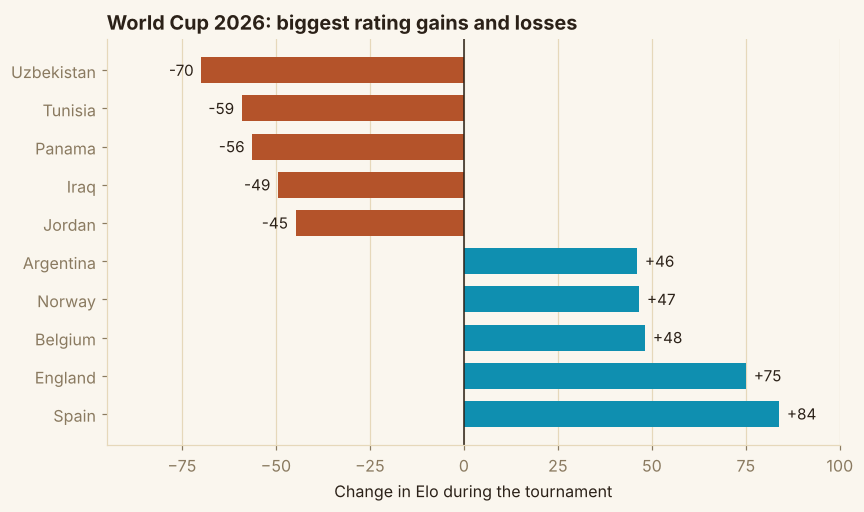

,Uzbekistan,Tunisia,Panama,Iraq,Jordan,Ecuador,New Zealand,Uruguay,Czech Republic,South Korea,...,Switzerland,DR Congo,Ghana,Egypt,Mexico,Argentina,Norway,Belgium,England,Spain
elo_change,-70,-59,-56,-49,-45,-44,-37,-36,-35,-31,...,35,36,37,40,44,46,47,48,75,84


In [33]:
WC_END = pd.Timestamp("2026-07-19")
wc_all = df[(df["tournament"] == "FIFA World Cup") & (df["date"] >= "2026-01-01")]
pre_wc, post_wc = {}, {}
for r in wc_all.sort_values("date").itertuples():
    pre_wc.setdefault(r.home_team, r.elo_h); pre_wc.setdefault(r.away_team, r.elo_a)
for r in df[df["date"] > WC_END].sort_values("date").itertuples():
    post_wc.setdefault(r.home_team, r.elo_h); post_wc.setdefault(r.away_team, r.elo_a)
change = pd.Series({t: post_wc.get(t, final_ratings[t]) - pre_wc[t] for t in pre_wc}).sort_values()

top_pre = pd.Series(pre_wc).sort_values(ascending=False)
print(f"{len(change)} teams played the 2026 World Cup.")
print(f"Before the tournament: {top_pre.index[0]} {top_pre.iloc[0]:,.0f}, {top_pre.index[1]} {top_pre.iloc[1]:,.0f} (gap {top_pre.iloc[0] - top_pre.iloc[1]:.0f} points)")
print("Winner: Spain (beat Argentina 1-0 in the final on 19 July 2026)\n")

show_n = 5
sel = pd.concat([change.head(show_n), change.tail(show_n)])
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.barh(sel.index[::-1], sel.values[::-1], color=[TEAL if v > 0 else TERRA for v in sel.values[::-1]], height=0.68)
for y, v in zip(range(len(sel)), sel.values[::-1]):
    ax.annotate(f"{v:+.0f}", (v, y), xytext=(5 if v > 0 else -5, 0), textcoords="offset points", ha="left" if v > 0 else "right", va="center", fontsize=10)
ax.axvline(0, color=INK, lw=1)
ax.set_xlim(-95, 100); ax.set_xlabel("Change in Elo during the tournament"); ax.grid(axis="y", visible=False)
ax.set_title("World Cup 2026: biggest rating gains and losses")
show(fig, "p10_wc_rating_change")
change.round(0).astype(int).rename("elo_change").to_frame().T

240 active teams.
               elo  rank_among_active
Morocco       1986                  9
Algeria       1824                 30
Egypt         1790                 35
Saudi Arabia  1749                 43
Jordan        1717                 55
Palestine     1589                 88


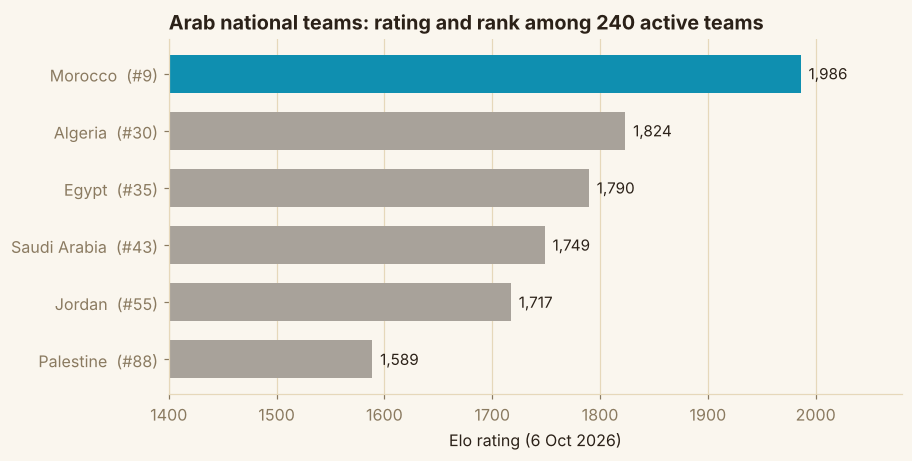

In [34]:
recent = set(df.loc[df["date"] >= "2024-01-01", "home_team"]) | set(df.loc[df["date"] >= "2024-01-01", "away_team"])
active = pd.Series(final_ratings)[lambda s: s.index.isin(recent)].sort_values(ascending=False)
rank = pd.Series(np.arange(1, len(active) + 1), index=active.index)
arab = ["Morocco", "Algeria", "Egypt", "Saudi Arabia", "Jordan", "Palestine"]
tbl = pd.DataFrame({"elo": active[arab].round(0).astype(int), "rank_among_active": rank[arab]})
print(f"{len(active)} active teams.")
print(tbl.to_string())

fig, ax = plt.subplots(figsize=(8.6, 4.2))
lab = [f"{n}  (#{rank[n]})" for n in arab]
ax.barh(lab[::-1], active[arab].values[::-1], color=[TEAL if n == "Morocco" else "#a8a29a" for n in arab[::-1]], height=0.66)
for y, v in enumerate(active[arab].values[::-1]):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_xlim(1400, 2080); ax.set_xlabel("Elo rating (6 Oct 2026)"); ax.grid(axis="y", visible=False)
ax.set_title("Arab national teams: rating and rank among 240 active teams")
show(fig, "p11_arab_teams")

## 16. Findings, limits and next steps

In [35]:
from IPython.display import Markdown, display
A_wc = wc['correct'].mean()
A = results["All test matches"]; B = results["Balanced (|Elo diff| <= 200)"]; W = results["World Cup 2026"]
b_lr = boot.set_index("model A").loc["LR, all features", "verdict"]
b_gb = boot.set_index("model A").loc["Gradient Boosting", "verdict"]
b_rf = boot.set_index("model A").loc["Random Forest", "verdict"]
b_en = boot.set_index("model A").loc["Ensemble", "verdict"]
display(Markdown(f"""
### What the numbers say

1. **The fair accuracy to beat is {always_home:.1%}** ("always predict a home win"), not 50%. The Elo-only logistic regression reaches **{A.loc['LR, Elo only','accuracy']:.1%}**, and its gain over the baseline is far larger than the uncertainty ({(acc_elo - always_home) * 100:+.1f} points, 95% range {lo * 100:+.1f} to {hi * 100:+.1f}).
2. **Elo does almost all the work.** A single rating-difference number cuts log loss from {A.loc['Prior','log_loss']:.3f} (prior) to {A.loc['LR, Elo only','log_loss']:.3f}. Recent form alone (5-match averages) gets to {A.loc['RF, form only','log_loss']:.3f}, and on balanced matches it is no better than the prior ({B.loc['RF, form only','log_loss']:.3f} vs {B.loc['Prior','log_loss']:.3f}).
3. **Extra features and fancier models help only a little.** The best model on log loss is **{A['log_loss'].drop(['Prior']).idxmin()}** ({A['log_loss'].drop(['Prior']).min():.3f}). Against Elo-only the paired bootstrap says: all-features logistic regression is *{b_lr}*, random forest *{b_rf}*, gradient boosting *{b_gb}*, ensemble *{b_en}*. Accuracy differences between these models (all around {A.drop(['Prior','RF, form only'])['accuracy'].min():.1%} to {A.drop(['Prior','RF, form only'])['accuracy'].max():.1%}) are well inside the ±0.8-point noise of 4,098 matches, so they should not be used to rank the models.
4. **Balanced matches are hard.** When the Elo gap is 200 or less, the ensemble reaches {B.loc['Ensemble','accuracy']:.1%} accuracy (log loss {B.loc['Ensemble','log_loss']:.3f}, prior {B.loc['Prior','log_loss']:.3f}). Most of the headline accuracy comes from the many mismatches, which are easy.
5. **World Cup 2026** (104 matches): the ensemble got {A_wc:.1%} right and had log loss {W.loc['Ensemble','log_loss']:.3f} (prior {W.loc['Prior','log_loss']:.3f}). With only 104 matches the accuracy has a margin of roughly ±{1.96 * (0.65 * 0.35 / 104) ** 0.5 * 100:.0f} points, so read it as consistent with the full test period, not as proof of anything extra.
6. **Draws are predicted as probabilities, not calls.** They are about {(y_idx == 1).mean():.0%} of matches, but are almost never the single most likely outcome.

### Limits

- **Results only.** No lineups, injuries, expected goals, odds or squad value. Most of the remaining uncertainty is information this data cannot contain.
- **Friendlies** are a third of the matches and are noisy (rotated squads), though the importance weight in Elo reduces their effect.
- **One split.** A single train/validation/test cut is fair but not exhaustive; a rolling-origin evaluation would be a stronger check.
- **Elo settings** were tuned on a small grid; the best value sat on its edge, but the differences were tiny.
- **Not betting advice.** Bookmaker odds contain information (and a margin) this model does not.

### Next steps

1. Add **market odds** as a benchmark: if the model cannot beat the odds, it should not be trusted for money.
2. Add **squad / player data** (club-level ratings, injuries) and see which of the extra signal is real.
3. Try **rolling-origin evaluation** and a **dynamic Elo** whose K adapts to each team's uncertainty.
4. Build a **simulation of a whole tournament** from the match probabilities.
"""))


### What the numbers say

1. **The fair accuracy to beat is 47.2%** ("always predict a home win"), not 50%. The Elo-only logistic regression reaches **60.7%**, and its gain over the baseline is far larger than the uncertainty (+13.5 points, 95% range +12.0 to +14.9).
2. **Elo does almost all the work.** A single rating-difference number cuts log loss from 1.054 (prior) to 0.870. Recent form alone (5-match averages) gets to 0.982, and on balanced matches it is no better than the prior (1.081 vs 1.081).
3. **Extra features and fancier models help only a little.** The best model on log loss is **LR, all features** (0.861). Against Elo-only the paired bootstrap says: all-features logistic regression is *better*, random forest *no clear difference*, gradient boosting *better*, ensemble *better*. Accuracy differences between these models (all around 60.7% to 60.9%) are well inside the ±0.8-point noise of 4,098 matches, so they should not be used to rank the models.
4. **Balanced matches are hard.** When the Elo gap is 200 or less, the ensemble reaches 50.0% accuracy (log loss 1.018, prior 1.081). Most of the headline accuracy comes from the many mismatches, which are easy.
5. **World Cup 2026** (104 matches): the ensemble got 66.3% right and had log loss 0.849 (prior 1.055). With only 104 matches the accuracy has a margin of roughly ±9 points, so read it as consistent with the full test period, not as proof of anything extra.
6. **Draws are predicted as probabilities, not calls.** They are about 23% of matches, but are almost never the single most likely outcome.

### Limits

- **Results only.** No lineups, injuries, expected goals, odds or squad value. Most of the remaining uncertainty is information this data cannot contain.
- **Friendlies** are a third of the matches and are noisy (rotated squads), though the importance weight in Elo reduces their effect.
- **One split.** A single train/validation/test cut is fair but not exhaustive; a rolling-origin evaluation would be a stronger check.
- **Elo settings** were tuned on a small grid; the best value sat on its edge, but the differences were tiny.
- **Not betting advice.** Bookmaker odds contain information (and a margin) this model does not.

### Next steps

1. Add **market odds** as a benchmark: if the model cannot beat the odds, it should not be trusted for money.
2. Add **squad / player data** (club-level ratings, injuries) and see which of the extra signal is real.
3. Try **rolling-origin evaluation** and a **dynamic Elo** whose K adapts to each team's uncertainty.
4. Build a **simulation of a whole tournament** from the match probabilities.
